MODULE 04 - MACHINE LEARNING BASICS

Dataset loaded successfully!

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Dataset shape: (150, 5)

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

Training records: 120
Testing records: 30

Model trained successfully!

Actual values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Predicted values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Model A

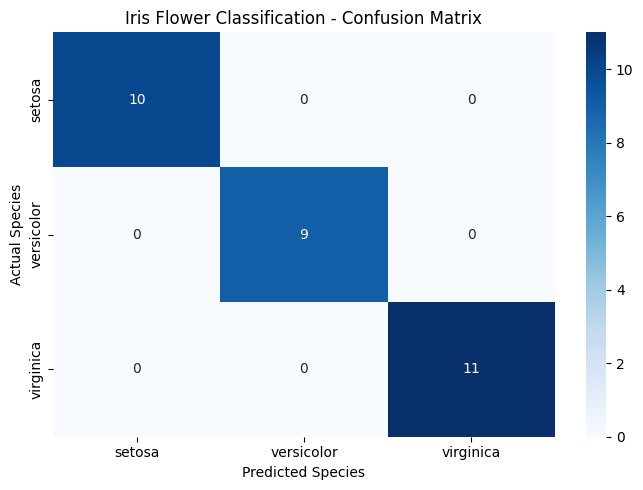


New Flower Prediction:
Predicted Species: setosa

Feature Importance:
petal length (cm)    0.906143
petal width (cm)     0.077186
sepal width (cm)     0.016670
sepal length (cm)    0.000000
dtype: float64


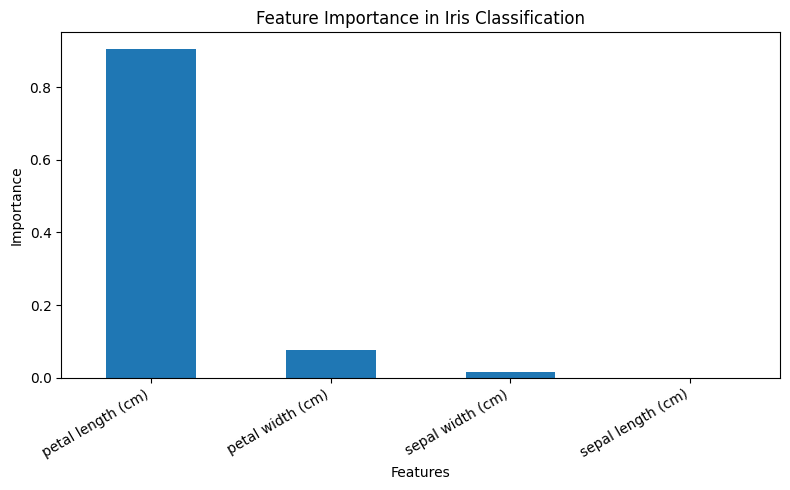


MODULE 04 COMPLETED SUCCESSFULLY!


In [1]:

# MODULE 04 - MACHINE LEARNING BASICS

# 1. Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("MODULE 04 - MACHINE LEARNING BASICS")
print("=" * 50)

# 2. Load the Iris dataset
iris = load_iris()

X = iris.data
y = iris.target

data = pd.DataFrame(X, columns=iris.feature_names)
data["species"] = iris.target_names[y]

print("\nDataset loaded successfully!")
print("\nFirst 5 rows:")
print(data.head())

print("\nDataset shape:", data.shape)
print("\nSpecies distribution:")
print(data["species"].value_counts())

# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# 4. Create and train the Decision Tree model
model = DecisionTreeClassifier(random_state=42)

model.fit(X_train, y_train)

print("\nModel trained successfully!")

# 5. Make predictions
y_pred = model.predict(X_test)

print("\nActual values:")
print(y_test)

print("\nPredicted values:")
print(y_pred)

# 6. Evaluate model performance
accuracy = accuracy_score(y_test, y_pred)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

# 7. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Iris Flower Classification - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.tight_layout()
plt.show()

# 8. Predict a new flower sample
sample = [[5.1, 3.5, 1.4, 0.2]]

prediction = model.predict(sample)

print("\nNew Flower Prediction:")
print("Predicted Species:", iris.target_names[prediction[0]])

# 9. Feature Importance
importance = pd.Series(
    model.feature_importances_,
    index=iris.feature_names
).sort_values(ascending=False)

print("\nFeature Importance:")
print(importance)

importance.plot(kind="bar", figsize=(8, 5))
plt.title("Feature Importance in Iris Classification")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("\nMODULE 04 COMPLETED SUCCESSFULLY!")
